<div style="background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); padding: 30px; border-radius: 8px; margin-bottom: 25px;">
    <h1 style="color: #f8fafc; font-family: 'Segoe UI', sans-serif; font-weight: 700; margin: 0; font-size: 2.2em;">Estratificación en PISA (2012-2022)</h1>
    <p style="color: #94a3b8; font-family: 'Segoe UI', sans-serif; margin: 8px 0 0 0; font-size: 1.1em;">Gerenación de estratos fijos inter-edicion para modelos comparativos</p>
</div>

En la modelización sistemas educativos, una decisión crítica de diseño consiste en delimitar con precisión qué variables definen al **contenedor institucional (el colegio)** y cuáles pertenecen al **agente individual (el estudiante y su familia)** de tal forma que puedan generarse comparativas precisas inter-edición e intra-escolar.



En la definición de los perfiles o estratos escolares se contemplo la evaluación de un conjunto amplio de variables candidatas para caracterizar el contenedor institucional:

* **Estatus socioeconómico agregado (`ESCS_medio_colegio`):** Promedio escolar del índice de estatus económico, social y cultural.Permitiría crear estratos sociales.
* **Titularidad y régimen financiero (`SCHLTYPE` / `PROPFUND`):** Naturaleza jurídica (público, concertado, privado) o porcentaje de financiación pública recibida.
* **Entorno territorial (`SC001Q01TA`):** Tamaño demográfico de la localidad donde se ubica el centro (rural vs. urbano).
* **Escala física del centro (`SCHSIZE`):** Volumen total de estudiantes matriculados.

Para garantizar la validez metodológica y evitar sesgos en la estimación de los efectos individuales (recursos del hogar vs. esfuerzo del estudiante), a continuación se realiza un **estudio empírico preliminar que justifica la exclusión del `ESCS_medio_colegio` y la selección exclusiva de variables exógenas y fijas** para la construcción de los perfiles institucionales.

# 1. *Carga de datos y librerías*

In [32]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

RUTA_DATOS_ANUALES = Path("../../data/raw/datos_anuales")
RUTA_ESTUDIANTES_2022 = RUTA_DATOS_ANUALES / "pisa2022_estudiantes.parquet"
RUTA_COLEGIOS_2022 = RUTA_DATOS_ANUALES / "pisa2022_colegios.parquet"

Cargamos los datos necesarios para los estratos dentro de `data/raw/datos_anuales` que contiene los arcivos parquet necesarios

In [33]:
# Cargamos únicamente las columnas estrictamente necesarias del nivel estudiante para optimizar RAM

cols_micro_2022 = ["CNT", "CNTSCHID", "CNTSTUID", "ESCS", "HOMEPOS", "W_FSTUWT"] 

df_alumnos_2022 = pd.read_parquet(RUTA_ESTUDIANTES_2022, columns=cols_micro_2022)

print((list(df_alumnos_2022.columns)))

['CNT', 'CNTSCHID', 'CNTSTUID', 'ESCS', 'HOMEPOS', 'W_FSTUWT']


# 2. Estudio del índice socio económico ESCS

El **Índice de Estatus Económico, Social y Cultural (`ESCS`)** es un indicador compuesto estandarizado por la OCDE en PISA para sintetizar el capital socioeconómico y cultural del hogar del estudiante

### Posibles estratos escolares basados en ESCS

Al agregar el valor individual del alumno al nivel de centro mediante el promedio ponderado (`ESCS_medio_colegio`), se podrían categorizar los colegios según el perfil socioeconómico de su alumnado:

1. **Estrato Socioeconómico Bajo:** Colegios en el tercil/cuartil inferior de `ESCS_medio_colegio` (entornos de vulnerabilidad socioeducativa).
2. **Estrato Socioeconómico Medio:** Colegios en los terciles/cuartiles intermedios.
3. **Estrato Socioeconómico Alto:** Colegios en el tercil/cuartil superior de `ESCS_medio_colegio` (entornos de alto capital sociocultural).

Cabe preguntarse
Las tres pregutas 1 si es un buen indice, y 2 cuanta correlacion tiene con los recursos del alumno
Se investiga en este cuaderno

## Calculo de la media ponderada `ESCS`

In [39]:
# Calculamos ESCS_medio_colegio ponderado por W_FSTUWT exclusivamente para evidenciar el sesgo

#Mascara para filtrar datos nulos
mask_val = df_alumnos_2022["ESCS"].notna() & df_alumnos_2022["W_FSTUWT"].notna()

#Copia local
df_temp_escs = df_alumnos_2022.loc[mask_val, ["CNT", "CNTSCHID", "ESCS", "W_FSTUWT"]].copy()


<div style=" background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); backdrop-filter: blur(4px); -webkit-backdrop-filter: blur(4px); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; color: inherit; margin: 20px 0; "> 
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;"> 💡 Ponderación muestral del ESCS </strong> 
  El <code>ESCS_medio_colegio</code> se calcula como una media ponderada por el peso final del estudiante (<code>W_FSTUWT</code>): 
  
  <span style="display: inline-flex; align-items: center; font-style: italic; font-family: 'Times New Roman', Times, serif; font-size: 1.1em; margin: 0 4px; vertical-align: middle;">
    <span style="text-decoration: overline; font-style: normal; margin-right: 1px;">x</span><sub>escuela</sub>&nbsp;=&nbsp;&sum;<sub>i</sub>x<sub>i</sub>w<sub>i</sub>&nbsp;/&nbsp;&sum;<sub>i</sub>w<sub>i</sub>
  </span>. 

  El código implementa esta fórmula en dos pasos: primero multiplica cada <code>ESCS</code> por su peso (numerador) y, tras el <code>groupby</code>, divide la suma de productos entre la suma de pesos (denominador). Dado que <code>W_FSTUWT</code> indica cuántos estudiantes de 15 años de la población representa cada alumno encuestado, la ponderación es la práctica estándar recomendada por la OCDE para que el indicador estime la composición de la población del centro y no solo la de la muestra.
  
   En PISA 2022 los pesos apenas varían dentro de un mismo colegio , por lo que la media ponderada y la simple son prácticamente idénticas. Se mantiene la versión ponderada por rigor y coherencia metodológica. 
</div>




In [40]:
#Calculo del numerador
df_temp_escs["_escs_w"] = df_temp_escs["ESCS"] * df_temp_escs["W_FSTUWT"]

#Calculo de los coeficientes palos colegios
escs_meso = (
    df_temp_escs.groupby(["CNT", "CNTSCHID"], as_index=False) 
    .agg(_num=("_escs_w", "sum"), _den=("W_FSTUWT", "sum")) 
)
escs_meso["ESCS_medio_colegio"] = escs_meso["_num"] / escs_meso["_den"] #Calclo de la media ponderada para cada colegio

#Juntamos la media en el dataframe de alumnos 
df_sesgo = (
    df_alumnos_2022[["CNT", "CNTSCHID", "HOMEPOS"]]
    .merge(escs_meso[["CNT", "CNTSCHID", "ESCS_medio_colegio"]], on=["CNT", "CNTSCHID"], how="inner")
    .dropna(subset=["ESCS_medio_colegio", "HOMEPOS"])
)

## Calculo de la correlacion con HOMEPOS ( Variable de recursos )

In [41]:
#Calculamos la correlacion de pearson entre las dos varuables
corr_pearson = df_sesgo["ESCS_medio_colegio"].corr(df_sesgo["HOMEPOS"])

#TODO Quitar lo de la semilla, ya se pone al principio

print(
    f"Correlación de Pearson (ESCS_medio_colegio vs HOMEPOS): r = {corr_pearson:.4f} "
    f"(N = {len(df_sesgo):,} alumnos)"
)

Correlación de Pearson (ESCS_medio_colegio vs HOMEPOS): r = 0.5228 (N = 261,003 alumnos)


Una correlacion simple de ambas variables nos da una **correlacion medio-moderada**

## Visualización ESCS Vs. HOMEPOS

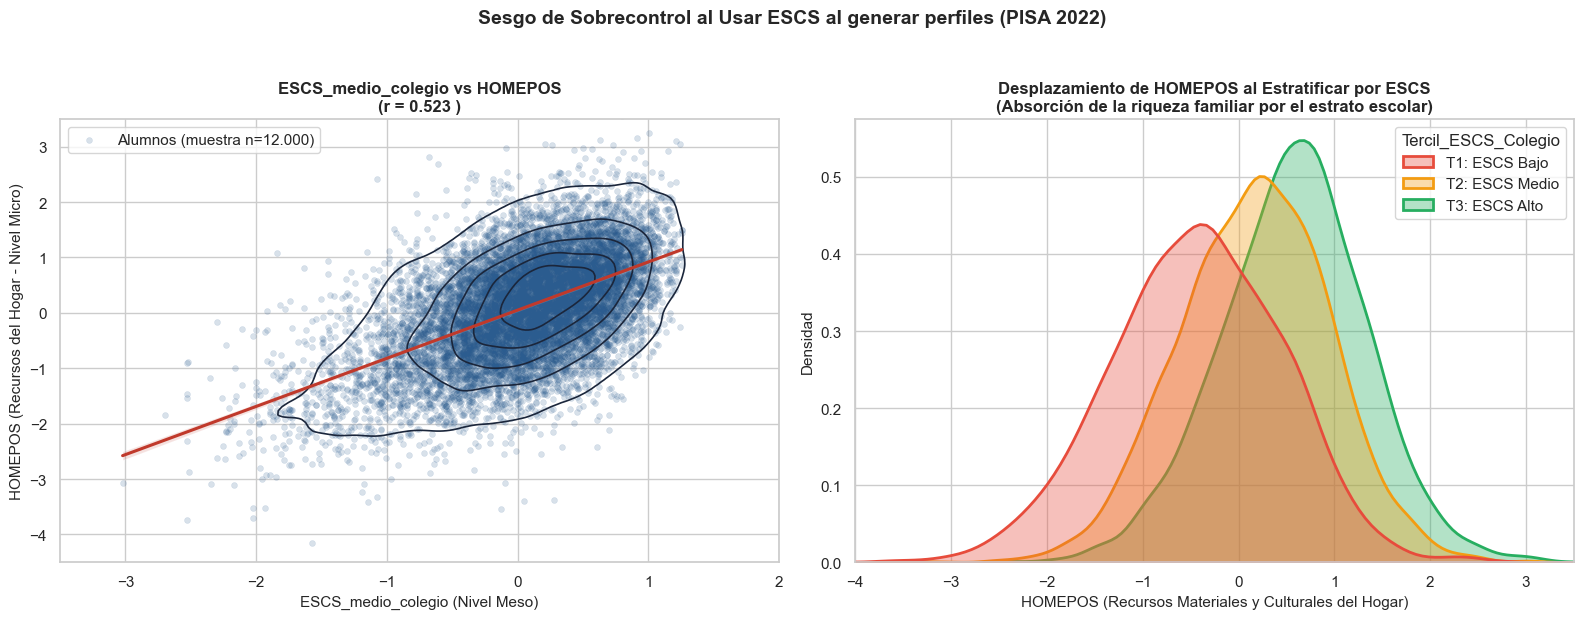

In [42]:

# Muestra aleatoria reproducible para renderizar con fluidez el Scatter + KDE
df_muestra_plot = df_sesgo.sample(n=min(12_000, len(df_sesgo)), random_state=42).copy()

#Dividimos en terciles los diferentes estratos de acuerdo al ESCS
df_muestra_plot["Tercil_ESCS_Colegio"] = pd.qcut(
    df_muestra_plot["ESCS_medio_colegio"],
    q=3,
    labels=["T1: ESCS Bajo", "T2: ESCS Medio", "T3: ESCS Alto"],
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel Izquierdo: Scatter Plot + Contornos KDE + Regresión lineal
sns.scatterplot(
    data=df_muestra_plot,
    x="ESCS_medio_colegio",
    y="HOMEPOS",
    alpha=0.18,
    s=18,
    color="#2b5c8f",
    edgecolor=None,
    ax=axes[0],
    label="Alumnos (muestra n=12.000)",
)
sns.kdeplot(
    data=df_muestra_plot,
    x="ESCS_medio_colegio",
    y="HOMEPOS",
    levels=6,
    color="#1b263b",
    linewidths=1.2,
    ax=axes[0],
)
sns.regplot(
    data=df_muestra_plot,
    x="ESCS_medio_colegio",
    y="HOMEPOS",
    scatter=False,
    color="#c0392b",
    line_kws={"linewidth": 2.2, "label": f"Tendencia lineal (r = {corr_pearson:.2f})"},
    ax=axes[0],
)
axes[0].set_title(
    "ESCS_medio_colegio vs HOMEPOS\n"
    f"(r = {corr_pearson:.3f} )",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("ESCS_medio_colegio (Nivel Meso)", fontsize=11)
axes[0].set_ylabel("HOMEPOS (Recursos del Hogar - Nivel Micro)", fontsize=11)
axes[0].set_xlim(-3.5, 2.0)
axes[0].set_ylim(-4.5, 3.5)
axes[0].legend(loc="upper left")

# Panel Derecho: KDE de HOMEPOS condicionado al tercil de ESCS_medio_colegio
sns.kdeplot(
    data=df_muestra_plot,
    x="HOMEPOS",
    hue="Tercil_ESCS_Colegio",
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=2,
    palette=["#e74c3c", "#f39c12", "#27ae60"],
    ax=axes[1],
)
axes[1].set_title(
    "Desplazamiento de HOMEPOS al Estratificar por ESCS\n"
    "(Absorción de la riqueza familiar por el estrato escolar)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("HOMEPOS (Recursos Materiales y Culturales del Hogar)", fontsize=11)
axes[1].set_ylabel("Densidad", fontsize=11)
axes[1].set_xlim(-4.0, 3.5)

fig.suptitle(
    "Sesgo de Sobrecontrol al Usar ESCS al generar perfiles (PISA 2022)",
    fontsize=14,
    fontweight="bold",
    y=1.03,
)
fig.tight_layout()
plt.show()




## ¿ Porqué descartamos ESCS ?


1. **Naturaleza de origen familiar, no institucional:** El índice `ESCS` (*Economic, Social and Cultural Status*) de PISA es un constructo compuesto por el nivel educativo parental (`PARED`), el estatus ocupacional más alto de los padres (`HISEI`) y las posesiones materiales y culturales del hogar (`HOMEPOS`). Por tanto, el `ESCS` no mide ningún atributo físico, administrativo ni organizativo del edificio escolar, sino el capital socioeconómico agregado de las familias que acuden a él.

2. **Absorción artificial de la varianza de la riqueza (`HOMEPOS`):** Dado que `HOMEPOS` es uno de los tres pilares constitutivos del `ESCS`, agrupar los colegios según su `ESCS_medio_colegio` equivale a estratificar indirectamente por el nivel de recursos materiales del hogar. Si el estrato meso ya captura la riqueza familiar, al estimar en el Nivel Micro el efecto de los **recursos familiares (`HOMEPOS`) frente al esfuerzo individual**, gran parte de la varianza de `HOMEPOS` habrá sido absorbida por el estrato, sesgando a la baja su verdadero impacto.

3. **Aislamiento limpio del contenedor físico:** Al sustituir el `ESCS_medio_colegio` por la **dimensión física de la matrícula (`SCHSIZE`)**, junto con la **titularidad/financiación (`SCHLTYPE`/`PROPFUND`)** y el **entorno geográfico (`SC001Q01TA`)**, construimos perfiles **100 % institucionales**. De este modo, el estrato controla estrictamente por la escala, administración y localización del centro, dejando la riqueza familiar (`HOMEPOS`) y el esfuerzo del alumno libres de colinealidad inducida.

A continuación, demostramos visualmente esta colinealidad estructural enfrentando `ESCS_medio_colegio` contra `HOMEPOS` del alumno en los microdatos reales de PISA 2022.



# 3. ¿SCHLTYPE o PROPFUND? 

Descartado el uso del estatus socioeconómico en el apartado anterior, pasamos a construir los estratos exclusivamente a partir de **variables institucionales y morfológicas del centro educativo**:

1. **Titularidad / Régimen de Financiación (`SCHLTYPE` vs `PROPFUND`):** Distingue la naturaleza jurídica y financiera de la escuela. En los cuestionarios de dirección de PISA existen dos vías para capturar este eje:
   * La variable categórica derivada **`SCHLTYPE`** (que clasifica los centros en *Públicos*, *Privados Concertados/Dependientes del Gobierno* y *Privados Independientes*).
   * La variable continua **`PROPFUND`** (proveniente de las variantes de la pregunta `SC016Q01`: `SC016Q01JA` / `SC016Q01TA`, que recoge el porcentaje exacto de financiación procedente del gobierno).

2. **Entorno Físico (`SC001Q01TA`):** Captura el tamaño demográfico del municipio en el que se ubica físicamente la escuela (desde aldeas rurales hasta grandes áreas metropolitanas).

3. **Dimensión del Centro (`SCHSIZE`):** Mide el volumen total de matrícula escolar, reflejando la escala física y organizativa de las instalaciones.


### El problema de los datos faltantes

Por motivos de confidencialidad estadística o falta de respuesta de los directores, la cobertura de `SCHLTYPE` y `PROPFUND` varía sustancialmente entre países. Para maximizar la validez externa del estudio sin recurrir a imputaciones artificiales entre sistemas educativos distintos veremos que variable permite obtener la mayor representación de los colegios. Para ello:

1. Calculamos el porcentaje de valores nulos (`NaN`) por país (`CNT`) tanto en `SCHLTYPE` como en `PROPFUND` y los comparamos.

2.  Establecemos un umbral de viabilidad nacional del **50 % de nulos**: cualquier país que supere el 50 % de datos faltantes en la variable elegida se considera inviable en esa dimensión. La lógica condicional selecciona automáticamente como **variable ganadora** aquella que descarta menos países (y, en caso de empate en países salvados, la que conserva el mayor número absoluto de colegios válidos).

In [43]:
#Carga exclusiva de las variables institucionales de interés
esquema_col_2022 = set(pq.read_schema(RUTA_COLEGIOS_2022).names)
col_propfund_raw = "SC016Q01JA" if "SC016Q01JA" in esquema_col_2022 else "SC016Q01TA"

cols_institucionales = ["CNT", "CNTSCHID", "SCHLTYPE", col_propfund_raw, "SC001Q01TA", "SCHSIZE"]
df_colegios_raw = pd.read_parquet(RUTA_COLEGIOS_2022, columns=cols_institucionales).rename(
    columns={col_propfund_raw: "PROPFUND"}
)

### Caculo de los nulos

In [ ]:

UMBRAL_NULOS_PAIS = 50.0
candidatas = ["SCHLTYPE", "PROPFUND"]
resumen = []

# Agregación a nivel de colegio (['CNT', 'CNTSCHID']) mediante .first() -> Asignamos el primer valor encontrado a todos los alumnos de ese colegio dado que es comun
df_colegios_2022 = (
    df_colegios_raw.groupby(["CNT", "CNTSCHID"], as_index=False)
    .agg(
        SCHLTYPE=("SCHLTYPE", "first"),
        PROPFUND=("PROPFUND", "first"),
        SC001Q01TA=("SC001Q01TA", "first"),
        SCHSIZE=("SCHSIZE", "first"),
    )
)

# Cálculo del % de NaNs por país entre SCHLTYPE y PROPFUND
nulos_pais = (
    df_colegios_2022.groupby("CNT")[["SCHLTYPE", "PROPFUND"]]
    .apply(lambda g: g.isna().mean() * 100)
    .reset_index()
)
nulos_pais["_orden"] = nulos_pais[["SCHLTYPE", "PROPFUND"]].mean(axis=1)
nulos_pais = nulos_pais.sort_values("_orden", ascending=False).drop(columns="_orden")

# 1. Generar datos para la tabla
for var in candidatas:
    paises_descartados = sorted(nulos_pais.loc[nulos_pais[var] > UMBRAL_NULOS_PAIS, "CNT"].tolist())
    colegios_validos = df_colegios_2022.loc[~df_colegios_2022["CNT"].isin(paises_descartados), var].notna().sum()
    
    resumen.append({
        "Variable": var,
        "Países Salvados": len(nulos_pais) - len(paises_descartados),
        "Países Descartados (N)": len(paises_descartados),
        "Colegios Válidos": int(colegios_validos),
        "Lista Países Descartados": paises_descartados
    })

df_comparativa = pd.DataFrame(resumen)

#  Mostrar la tabla comparativa
display(df_comparativa.drop(columns=["Lista Países Descartados"]))

# 3. Seleccionar la variable ganadora y aislar los países a descartar
idx_ganadora = df_comparativa.sort_values(by=["Países Salvados", "Colegios Válidos"], ascending=False).index[0]
variable_ganadora = df_comparativa.loc[idx_ganadora, "Variable"]
paises_excluidos = df_comparativa.loc[idx_ganadora, "Lista Países Descartados"]

print(f"\n-> Variable a utilizar: {variable_ganadora}")
print(f"-> Países excluidos: {paises_excluidos}\n")

# 4. Limpieza final del DataFrame
cols_limpieza = [variable_ganadora, "SC001Q01TA", "SCHSIZE"]

df_colegios_2022 = (
    df_colegios_2022.loc[~df_colegios_2022["CNT"].isin(paises_excluidos)]
    .dropna(subset=cols_limpieza)
    .reset_index(drop=True)
)

print(f"Dataset listo: {len(df_colegios_2022):,} colegios completos en {df_colegios_2022['CNT'].nunique()} países.")

,Variable,Países Salvados,Países Descartados (N),Colegios Válidos
0,SCHLTYPE,28,5,8726
1,PROPFUND,28,5,8256



-> Variable a utilizar: SCHLTYPE
-> Países excluidos: ['AUT', 'BEL', 'IRL', 'ISR', 'NOR']

Dataset listo: 6,987 colegios completos en 25 países.


Escogemos SCHLTYPE, aunque ambos empatan en la cantidad de paises excluidos, SCHLTYPE permite quedarnos con mas colegios de la muestra

### Visualizacion de los nulos y umbra del 50%

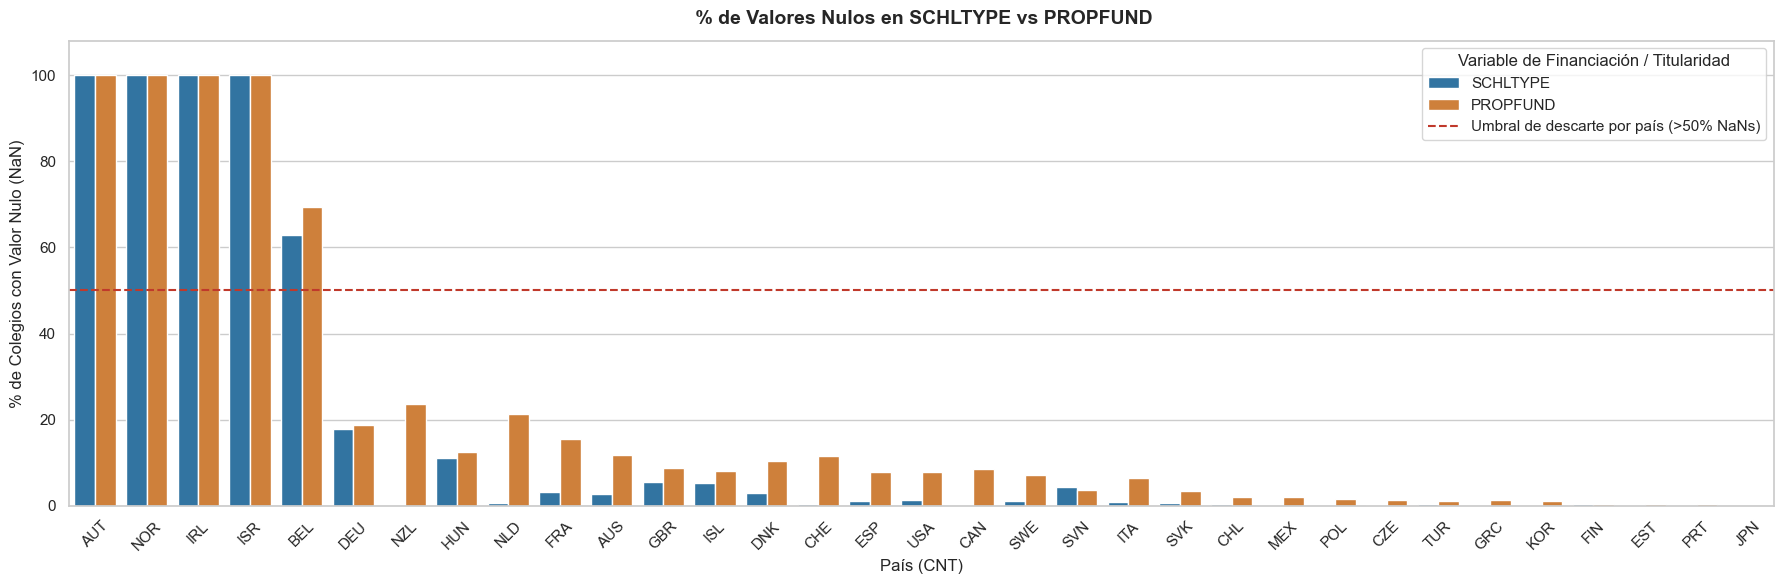

In [51]:
#TODO 
df_nulos_long = nulos_pais.melt(
    id_vars="CNT",
    value_vars=["SCHLTYPE", "PROPFUND"],
    var_name="Variable",
    value_name="Pct_Nulos",
)

# 4. Gráfico de barras agrupadas comparativo de % de NaNs por país
fig, ax = plt.subplots(figsize=(18, 6))
sns.barplot(
    data=df_nulos_long,
    x="CNT",
    y="Pct_Nulos",
    hue="Variable",
    palette={"SCHLTYPE": "#1f77b4", "PROPFUND": "#e67e22"},
    ax=ax,
)
ax.axhline(
    50.0,
    color="#c0392b",
    linestyle="--",
    linewidth=1.5,
    label="Umbral de descarte por país (>50% NaNs)",
)
ax.set_title(
    " % de Valores Nulos en SCHLTYPE vs PROPFUND",
    fontsize=14,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("País (CNT)", fontsize=12)
ax.set_ylabel("% de Colegios con Valor Nulo (NaN)", fontsize=12)
ax.set_ylim(0, 108)
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Variable de Financiación / Titularidad", loc="upper right")
fig.tight_layout()
plt.show()


Existe una atribución mayor de porcentaje de nulos para PROPFOUND, aunque ambos presentan la misma cantidad de paises 

# 3. Creación de Estratos Institucionales (Reglas Fijas)

Con el directorio de escuelas depurado, construimos el **«laboratorio estático»** discretizando las tres dimensiones físicas y administrativas mediante reglas fijas. Al prescindir del nivel socioeconómico, garantizamos que los estratos representen exclusivamente **tipos de infraestructura y gestión escolar**:

1. **Financiación / Titularidad (`SCHLTYPE` / `PROPFUND`):**
   * Empleando la variable ganadora `SCHLTYPE` (codificación oficial OCDE PISA: `3 = Público`, `2 = Privado dependiente del gobierno / Concertado`, `1 = Privado independiente`), generamos los códigos **`PUB`** (*Público*), **`CON`** (*Concertado*) y **`PRI`** (*Privado*). Si en otra edición ganase `PROPFUND`, se aplica la regla equivalente ($\ge 90\% \rightarrow$ `PUB`, $50\text{–}89,9\% \rightarrow$ `CON`, $<50\% \rightarrow$ `PRI`).
2. **Entorno Físico (`SC001Q01TA`):**
   * Colapsamos la escala demográfica en dos contextos territoriales: **`RUR`** (*Rural*, para aldeas $<3.000$ hab. y pueblos pequeños de $3.000$ a $15.000$ hab., códigos `1` y `2`) y **`URB`** (*Urbano*, para ciudades desde $15.000$ hab. hasta grandes áreas metropolitanas, códigos `3`, `4`, `5` y `6`).
3. **Dimensión del Centro (`SCHSIZE`):**
   * Discretizamos el tamaño de la matrícula escolar en **3 terciles estáticos** mediante `pd.qcut`: **`PEQ`** (*Escuela Pequeña*), **`MED`** (*Instituto Mediano*) y **`MACRO`** (*Macro-Instituto*).

Finalmente, ensamblamos dos columnas paralelas para cada colegio:
* **`PERFIL_CODE`:** Identificador corto ideal para regresiones, agrupaciones y ejes gráficos (ej. `PUB_URB_MACRO`).
* **`PERFIL_DESC`:** Descripción semántica legible para tablas e interpretación en la memoria del TFM (ej. `Público | Urbano | Macro-Instituto`).

In [52]:
# 1. Diccionarios de mapeo para Financiación (SCHLTYPE / PROPFUND)

#limpieza del dataset final sin nulos antes de generar los perfiles 
df_colegios_2022 = df_colegios_2022.dropna(subset=["SCHLTYPE","SC001Q01TA", "SCHSIZE"]).reset_index(drop=True)


MAPEO_SCHLTYPE_CODE = {3.0: "PUB", 2.0: "CON", 1.0: "PRI"}
MAPEO_FIN_DESC = {
    "PUB": "Público",
    "CON": "Concertado",
    "PRI": "Privado",
}

if variable_ganadora == "SCHLTYPE":
    df_colegios_2022["FIN_CODE"] = df_colegios_2022["SCHLTYPE"].map(MAPEO_SCHLTYPE_CODE)
else:
    df_colegios_2022["FIN_CODE"] = np.select(
        [df_colegios_2022["PROPFUND"] >= 90.0, df_colegios_2022["PROPFUND"] >= 50.0],
        ["PUB", "CON"],
        default="PRI",
    )
df_colegios_2022["FIN_DESC"] = df_colegios_2022["FIN_CODE"].map(MAPEO_FIN_DESC)

# 2. Mapeo de Entorno Físico (SC001Q01TA: 1, 2 -> RUR; 3, 4, 5, 6 -> URB)
MAPEO_UBIC_CODE = {1.0: "RUR", 2.0: "RUR", 3.0: "URB", 4.0: "URB", 5.0: "URB", 6.0: "URB"}
MAPEO_UBIC_DESC = {"RUR": "Rural", "URB": "Urbano"}

df_colegios_2022["UBIC_CODE"] = df_colegios_2022["SC001Q01TA"].map(MAPEO_UBIC_CODE)
df_colegios_2022["UBIC_DESC"] = df_colegios_2022["UBIC_CODE"].map(MAPEO_UBIC_DESC)

# 3. Discretización de SCHSIZE en 3 terciles estáticos (PEQ, MED, MACRO)
CODIGOS_TAM = ["PEQ", "MED", "MACRO"]
MAPEO_TAM_DESC = {
    "PEQ": "Escuela Pequeña",
    "MED": "Instituto Mediano",
    "MACRO": "Macro-Instituto",
}

df_colegios_2022["TAM_CODE"], cortes_schsize = pd.qcut(
    df_colegios_2022["SCHSIZE"],
    q=3,
    labels=CODIGOS_TAM,
    retbins=True,
)
df_colegios_2022["TAM_CODE"] = df_colegios_2022["TAM_CODE"].astype(str)
df_colegios_2022["TAM_DESC"] = df_colegios_2022["TAM_CODE"].map(MAPEO_TAM_DESC)

print(
    f"Cortes de terciles de SCHSIZE (nº de alumnos matriculados):\n"
    f"  • PEQ   (Escuela Pequeña):   [{cortes_schsize[0]:.0f} - {cortes_schsize[1]:.0f}] alumnos\n"
    f"  • MED   (Instituto Mediano): ({cortes_schsize[1]:.0f} - {cortes_schsize[2]:.0f}] alumnos\n"
    f"  • MACRO (Macro-Instituto):   ({cortes_schsize[2]:.0f} - {cortes_schsize[3]:.0f}] alumnos\n"
)

# 4. Concatenación para crear PERFIL_CODE y PERFIL_DESC
df_colegios_2022["PERFIL_CODE"] = (
    df_colegios_2022["FIN_CODE"]
    + "_"
    + df_colegios_2022["UBIC_CODE"]
    + "_"
    + df_colegios_2022["TAM_CODE"]
)
df_colegios_2022["PERFIL_DESC"] = (
    df_colegios_2022["FIN_DESC"]
    + " | "
    + df_colegios_2022["UBIC_DESC"]
    + " | "
    + df_colegios_2022["TAM_DESC"]
)

# Tabla de frecuencias (value_counts) de los perfiles institucionales
mapa_code_desc = (
    df_colegios_2022[["PERFIL_CODE", "PERFIL_DESC"]]
    .drop_duplicates()
    .set_index("PERFIL_CODE")["PERFIL_DESC"]
)
frecuencias_institucionales = (
    df_colegios_2022["PERFIL_CODE"]
    .value_counts()
    .rename_axis("PERFIL_CODE")
    .to_frame(name="N_COLEGIOS")
)
frecuencias_institucionales["PERFIL_DESC"] = frecuencias_institucionales.index.map(mapa_code_desc)
frecuencias_institucionales["%_COLEGIOS"] = (
    100 * frecuencias_institucionales["N_COLEGIOS"] / len(df_colegios_2022)
).round(2)
frecuencias_institucionales = frecuencias_institucionales[["PERFIL_DESC", "N_COLEGIOS", "%_COLEGIOS"]]

print(f"Distribución de los {len(df_colegios_2022):,} colegios en los 18 perfiles institucionales (PISA 2022):")
display(frecuencias_institucionales)

Cortes de terciles de SCHSIZE (nº de alumnos matriculados):
  • PEQ   (Escuela Pequeña):   [9 - 415] alumnos
  • MED   (Instituto Mediano): (415 - 819] alumnos
  • MACRO (Macro-Instituto):   (819 - 6425] alumnos

Distribución de los 6,987 colegios en los 18 perfiles institucionales (PISA 2022):


,PERFIL_DESC,N_COLEGIOS,%_COLEGIOS
PERFIL_CODE,,,
PUB_URB_MACRO,Público | Urbano | Macro-Instituto,1465,20.97
PUB_URB_MED,Público | Urbano | Instituto Mediano,1405,20.11
PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,1051,15.04
PUB_URB_PEQ,Público | Urbano | Escuela Pequeña,767,10.98
PUB_RUR_MED,Público | Rural | Instituto Mediano,517,7.40
CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,379,5.42
CON_URB_MED,Concertado | Urbano | Instituto Mediano,257,3.68
PUB_RUR_MACRO,Público | Rural | Macro-Instituto,241,3.45
CON_URB_PEQ,Concertado | Urbano | Escuela Pequeña,233,3.33


# 4. Fusión Micro-Meso

El paso final del pipeline consiste en transferir la etiqueta institucional del colegio (`PERFIL_CODE` y `PERFIL_DESC`) de vuelta al nivel **Micro (el estudiante)** mediante una fusión relacional por la clave compuesta `['CNT', 'CNTSCHID']`.

Con esta arquitectura alcanzamos el objetivo central del diseño experimental:
* **Contenedor institucional exógeno («ladrillos y administración»):** Cada alumno queda ubicado dentro de una «foto fija» de su escuela definida exclusivamente por su régimen de financiación (`PUB`/`CON`/`PRI`), su entorno demográfico (`RUR`/`URB`) y su escala física (`PEQ`/`MED`/`MACRO`).
* **Variables individuales libres para competir en el modelo final:** Al no haber utilizado `ESCS` ni `HOMEPOS` en la construcción del estrato escolar, tanto los **recursos familiares del estudiante (`HOMEPOS_alumno`)** como sus **indicadores de esfuerzo y perseverancia (`EFFORT1`, `PERSEVAGR`)** conservan intacta su varianza natural dentro de cada tipo de centro, permitiendo estimar sin sesgo de atenuación su contribución relativa al rendimiento académico.

In [53]:
# 1. Merge del dataframe de colegios limpio de vuelta al dataframe de estudiantes por ['CNT', 'CNTSCHID']
cols_meso_merge = [
    "CNT",
    "CNTSCHID",
    "SCHLTYPE",
    "SC001Q01TA",
    "SCHSIZE",
    "PERFIL_CODE",
    "PERFIL_DESC",
]

df_laboratorio_2022 = df_alumnos_2022.merge(
    df_colegios_2022[cols_meso_merge],
    on=["CNT", "CNTSCHID"],
    how="inner",
    validate="many_to_one",
)

print(
    f"Fusión Micro-Meso completada con éxito:\n"
    f"  • Alumnos con Perfil Institucional asignado: {len(df_laboratorio_2022):,} "
    f"(de {len(df_alumnos_2022):,} totales en 2022)\n"
    f"  • Colegios representados:                    {df_laboratorio_2022['CNTSCHID'].nunique():,}\n"
    f"  • Países en el laboratorio:                  {df_laboratorio_2022['CNT'].nunique()}\n"
)

# 2. Comprobación visual de las columnas relevantes: Alumno, Perfil Institucional y Variables Micro libres
columnas_comprobacion = [
    "CNT",
    "CNTSCHID",
    "CNTSTUID",
    "PERFIL_CODE",
    "PERFIL_DESC",
    "HOMEPOS",
] + ["W_FSTUWT"]

print("Muestra del Laboratorio Micro-Meso (Alumno + Contenedor Institucional + Recursos y Esfuerzo libres):")
display(
    df_laboratorio_2022.dropna(subset=["HOMEPOS"] )[columnas_comprobacion].head(10)
)

# 3. Resumen de distribución de estudiantes por PERFIL_CODE
frecuencias_alumnos_inst = (
    df_laboratorio_2022["PERFIL_CODE"]
    .value_counts()
    .rename_axis("PERFIL_CODE")
    .to_frame(name="N_ALUMNOS")
)
frecuencias_alumnos_inst["PERFIL_DESC"] = frecuencias_alumnos_inst.index.map(mapa_code_desc)
frecuencias_alumnos_inst["%_ALUMNOS"] = (
    100 * frecuencias_alumnos_inst["N_ALUMNOS"] / len(df_laboratorio_2022)
).round(2)
frecuencias_alumnos_inst = frecuencias_alumnos_inst[["PERFIL_DESC", "N_ALUMNOS", "%_ALUMNOS"]]

print("\nDistribución de estudiantes por Perfil Institucional en el Laboratorio (PISA 2022):")
display(frecuencias_alumnos_inst)

Fusión Micro-Meso completada con éxito:
  • Alumnos con Perfil Institucional asignado: 186,094 (de 268,610 totales en 2022)
  • Colegios representados:                    6,987
  • Países en el laboratorio:                  25

Muestra del Laboratorio Micro-Meso (Alumno + Contenedor Institucional + Recursos y Esfuerzo libres):


,CNT,CNTSCHID,CNTSTUID,PERFIL_CODE,PERFIL_DESC,HOMEPOS,W_FSTUWT
0,AUS,3600477,3600001,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,2.6992,21.48539
1,AUS,3600016,3600002,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,1.4398,26.35004
2,AUS,3600669,3600004,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,0.9612,34.42706
3,AUS,3600495,3600006,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,-0.9616,30.61080
4,AUS,3600325,3600008,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,-1.4897,8.85803
5,AUS,3600733,3600009,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,0.2102,22.70024
6,AUS,3600266,3600010,CON_URB_PEQ,Concertado | Urbano | Escuela Pequeña,0.7169,17.29327
7,AUS,3600671,3600012,CON_URB_MED,Concertado | Urbano | Instituto Mediano,0.5447,3.91793
8,AUS,3600701,3600015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,-0.5671,12.26490
9,AUS,3600334,3600016,CON_URB_PEQ,Concertado | Urbano | Escuela Pequeña,0.2692,5.27367



Distribución de estudiantes por Perfil Institucional en el Laboratorio (PISA 2022):


,PERFIL_DESC,N_ALUMNOS,%_ALUMNOS
PERFIL_CODE,,,
PUB_URB_MACRO,Público | Urbano | Macro-Instituto,43823,23.55
PUB_URB_MED,Público | Urbano | Instituto Mediano,42643,22.91
PUB_URB_PEQ,Público | Urbano | Escuela Pequeña,19348,10.40
PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,18971,10.19
PUB_RUR_MED,Público | Rural | Instituto Mediano,13951,7.50
CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,11184,6.01
CON_URB_MED,Concertado | Urbano | Instituto Mediano,8080,4.34
PUB_RUR_MACRO,Público | Rural | Macro-Instituto,7051,3.79
PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,5426,2.92


# Limpieza de Memoria

In [ ]:
del df_temp_escs, escs_meso, df_sesgo, df_muestra_plot,df_colegios_raw
